# Figure S5

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_pupil_data_raw,
    load_pupilbetas_preprocessed,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
MIN_TRIALS_CORR = 20

### Figure S5: peak GLM-validation timebin per participant
Same per-(dataset, timebin, sub) correlation between the raw baseline-corrected pupil signal and the GLM-deconvolved amplitude as `figures_draft_notebook/figure4_v2.ipynb`'s Panel 3, but response-aligned only and reduced differently: instead of averaging the correlation across subjects at each timebin, each participant's own *peak*-correlation timebin is taken (`idxmax` of `r` within each dataset/sub group), and the distribution of those per-participant peak timebins is histogrammed per dataset. Same trial-count floor (`MIN_TRIALS_CORR = 20`) and exclusion filters as Panel 3.

Peak-correlation timebin per participant:
                   count      mean       std       min       25%       50%       75%       max
dataset                                                                                       
equalIndifference   31.0 -0.022893  0.287344 -0.580645 -0.193548 -0.064516  0.129032  0.580645
equalRange          29.0 -0.051168  0.355625 -0.709677 -0.322581 -0.064516  0.193548  0.709677
sheng2020           61.0  0.178741  0.327361 -0.967742 -0.064516  0.322581  0.451613  0.709677


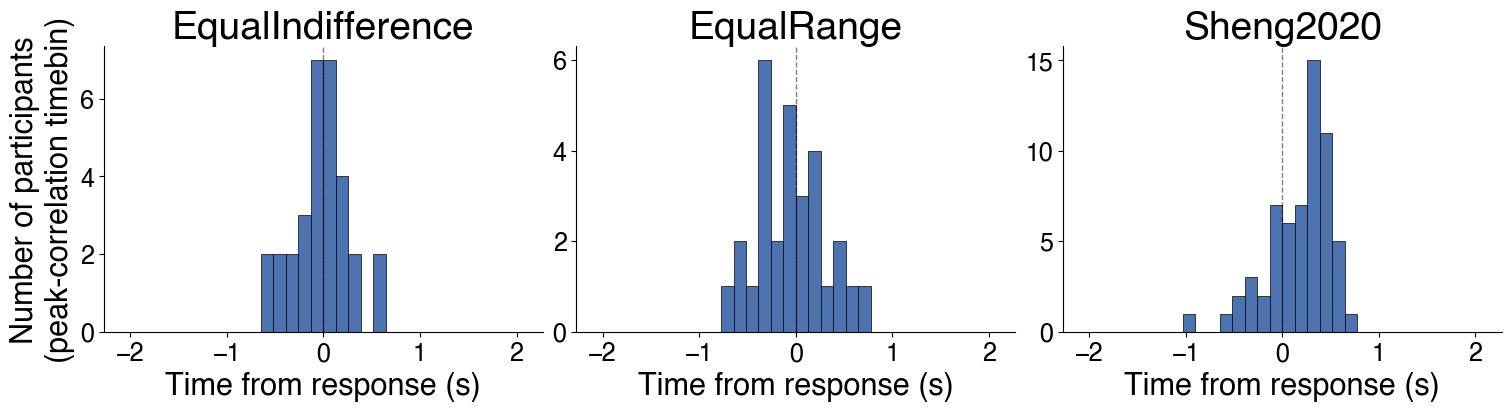

In [2]:
def compute_pupil_glm_correlation(alignment):
    raw = load_pupil_data_raw(alignment=alignment)
    raw = raw[raw["exclude"] == False].copy()
    raw["pupil_size_corrected"] = raw["pupil_size"] - raw["baseline_pupil"]

    betas = load_pupilbetas_preprocessed(exclude=True)
    merged = raw.merge(
        betas[["sub", "dataset", "trial", "pupil"]],
        on=["sub", "dataset", "trial"], how="inner",
    )

    rows = []
    for (dataset, timebin, sub), grp in merged.groupby(["dataset", "timebin", "sub"]):
        if len(grp) < MIN_TRIALS_CORR:
            continue
        if grp["pupil_size_corrected"].std() == 0 or grp["pupil"].std() == 0:
            continue
        r = grp["pupil_size_corrected"].corr(grp["pupil"])
        rows.append({"dataset": dataset, "timebin": timebin, "sub": sub, "r": r})

    return pd.DataFrame(rows)


per_sub_df = compute_pupil_glm_correlation(alignment="response")

best_timebin_df = (
    per_sub_df.loc[per_sub_df.groupby(["dataset", "sub"])["r"].idxmax()]
    .reset_index(drop=True)
)

print("Peak-correlation timebin per participant:")
print(best_timebin_df.groupby("dataset")["timebin"].describe().to_string())

HIST_COLOR = "#4C72B0"

timebins = sorted(per_sub_df["timebin"].unique())
step = timebins[1] - timebins[0]
bin_edges = np.array(timebins + [timebins[-1] + step]) - step / 2

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4), layout="constrained")

for ax, ds in zip(axes, DATASETS):
    vals = best_timebin_df[best_timebin_df["dataset"] == ds]["timebin"].values
    ax.hist(vals, bins=bin_edges, color=HIST_COLOR, edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    ax.set_xlabel("Time from response (s)")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Number of participants\n(peak-correlation timebin)")

fig.savefig("saved/figureS5.svg", dpi=300, bbox_inches="tight")
plt.show()